<a href="https://colab.research.google.com/github/mubasherhussain292/Authentication/blob/master/cifar100_assignment.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [8]:
import numpy as np

In [9]:
from os.path import join, exists

In [10]:
import tensorflow as tf
import matplotlib.pyplot as plt
import time
import pickle
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report

In [11]:
SEED = 42
tf.keras.utils.set_random_seed(SEED)
tf.__version__
tf.config.list_physical_devices('GPU')

[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]

In [ ]:
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.cifar100.load_data(label_mode='fine')

140156928/169001437 ━━━━━━━━━━━━━━━━━━━━ 3:15 7us/step

In [ ]:
x_all = np.concatenate((x_train, x_test), axis=0)
y_all = np.concatenate((y_train, y_test), axis=0)
y_all = y_all.flatten()

In [ ]:
y_all = y_all.flatten()
print("y_all shape:", y_all.shape)

In [ ]:
x_temp, x_test, y_temp, y_test = train_test_split(
    x_all, y_all, test_size=0.2, stratify=y_all, random_state=SEED
)
x_train, x_val, y_train, y_val = train_test_split(
    x_temp, y_temp, test_size=0.125, stratify=y_temp, random_state=SEED
)

In [ ]:
x_train = x_train.astype('float32') / 255.0
x_val   = x_val.astype('float32')   / 255.0
x_test  = x_test.astype('float32')  / 255.0

# ---------- Safety checks ----------
assert 0.9 < x_train.max() <= 1.0, "x_train normalization went wrong"
assert 0.9 < x_val.max()   <= 1.0, "x_val normalization went wrong"
assert 0.9 < x_test.max()  <= 1.0, "x_test normalization went wrong"

assert x_train.shape == (42000, 32, 32, 3), f"x_train shape wrong: {x_train.shape}"
assert x_val.shape   == (6000,  32, 32, 3), f"x_val shape wrong: {x_val.shape}"
assert x_test.shape  == (12000, 32, 32, 3), f"x_test shape wrong: {x_test.shape}"

# ---------- Clean output ----------
print(f"x_train shape: {x_train.shape}")
print(f"x_val shape  : {x_val.shape}")
print(f"x_test shape : {x_test.shape}")
print(f"x_train.min(): {x_train.min()}")
print(f"x_train.max(): {x_train.max()}")
print(f"x_val.max()  : {x_val.max()}")
print(f"x_test.max() : {x_test.max()}")
print(f"np.bincount(y_train)[:5]: {np.bincount(y_train)[:5]}")


In [ ]:
class_names = [
    'apple', 'aquarium_fish', 'baby', 'bear', 'beaver', 'bed', 'bee', 'beetle',
    'bicycle', 'bottle', 'bowl', 'boy', 'bridge', 'bus', 'butterfly', 'camel',
    'can', 'castle', 'caterpillar', 'cattle', 'chair', 'chimpanzee', 'clock',
    'cloud', 'cockroach', 'couch', 'crab', 'crocodile', 'cup', 'dinosaur',
    'dolphin', 'elephant', 'flatfish', 'forest', 'fox', 'girl', 'hamster',
    'house', 'kangaroo', 'keyboard', 'lamp', 'lawn_mower', 'leopard', 'lion',
    'lizard', 'lobster', 'man', 'maple_tree', 'motorcycle', 'mountain', 'mouse',
    'mushroom', 'oak_tree', 'orange', 'orchid', 'otter', 'palm_tree', 'pear',
    'pickup_truck', 'pine_tree', 'plain', 'plate', 'poppy', 'porcupine',
    'possum', 'rabbit', 'raccoon', 'ray', 'road', 'rocket', 'rose',
    'sea', 'seal', 'shark', 'shrew', 'skunk', 'skyscraper', 'snail', 'snake',
    'spider', 'squirrel', 'streetcar', 'sunflower', 'sweet_pepper', 'table',
    'tank', 'telephone', 'television', 'tiger', 'tractor', 'train', 'trout',
    'tulip', 'turtle', 'wardrobe', 'whale', 'willow_tree', 'wolf', 'woman', 'worm'
]

print("len:", len(class_names))   # 100
print("first:", class_names[0])   # apple

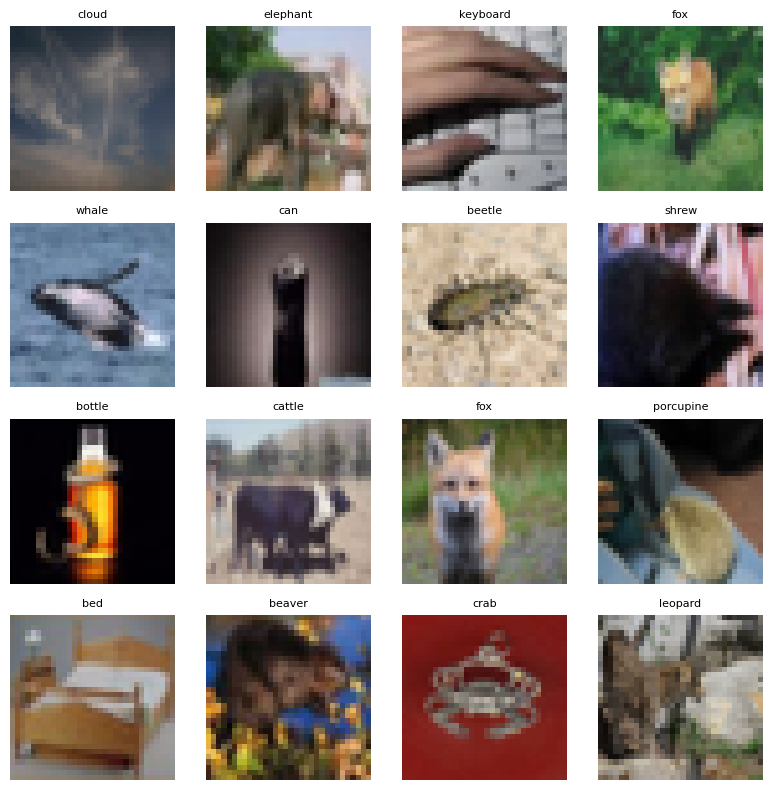

In [20]:

fig, axes = plt.subplots(4, 4, figsize=(8, 8))

for i, ax in enumerate(axes.flat):
    ax.imshow(x_train[i])
    ax.set_title(class_names[y_train[i]], fontsize=8)
    ax.axis('off')

plt.tight_layout()
plt.show()

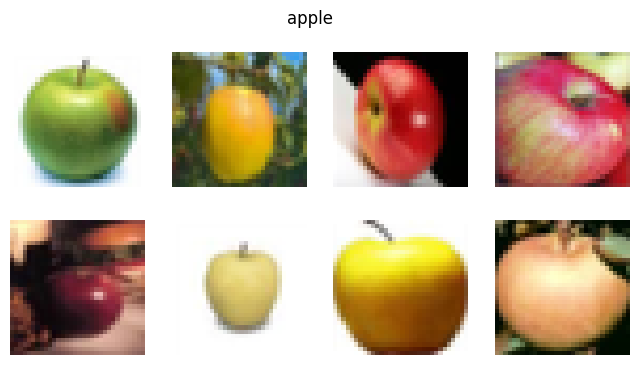

In [21]:
idx = np.where(y_train == 0)[0][:8]

fig, axes = plt.subplots(2, 4, figsize=(8, 4))
for ax, i in zip(axes.flat, idx):
    ax.imshow(x_train[i])
    ax.axis('off')
plt.suptitle(class_names[0])
plt.show()

In [22]:
from tensorflow.keras import layers, models

def build_alexnet(num_classes=100):
    model = models.Sequential([
        layers.Input(shape=(32, 32, 3)),

        layers.Conv2D(64, 3, padding='same', activation='relu'),
        layers.MaxPooling2D(2),                      # -> 16x16

        layers.Conv2D(192, 3, padding='same', activation='relu'),
        layers.MaxPooling2D(2),                      # -> 8x8

        layers.Conv2D(384, 3, padding='same', activation='relu'),
        layers.Conv2D(256, 3, padding='same', activation='relu'),
        layers.Conv2D(256, 3, padding='same', activation='relu'),
        layers.MaxPooling2D(2),                      # -> 4x4

        layers.Flatten(),                            # 3D maps -> 1D vector

        layers.Dense(1024, activation='relu'),
        layers.Dropout(0.5),
        layers.Dense(1024, activation='relu'),
        layers.Dropout(0.5),
        layers.Dense(num_classes, activation='softmax'),  # 100 probabilities
    ])
    return model

model = build_alexnet()
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 32, 32, 64)     │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 16, 16, 192)    │       110,784 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 8, 8, 192)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 8, 8, 384)      │       663,936 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 8, 8, 256)      │       884,992 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 8, 8, 256)      │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 4, 4, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1024)           │     4,195,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1024)           │     1,049,600 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 100)            │       102,500 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 7,599,012 (28.99 MB)

 Trainable params: 7,599,012 (28.99 MB)

 Non-trainable params: 0 (0.00 B)

In [24]:


model = build_alexnet()

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

callbacks = [
    tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=5,
                                     restore_best_weights=True),
    tf.keras.callbacks.ModelCheckpoint('alexnet_best.keras', monitor='val_loss',
                                       save_best_only=True),
    tf.keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=2),
]

In [25]:
start = time.time()
history_check = model.fit(
    x_train, y_train,
    validation_data=(x_val, y_val),
    epochs=3,
    batch_size=128,
    callbacks=callbacks
)
train_time_check = time.time() - start
print(f"3-epoch training time: {train_time_check/60:.2f} min ({train_time_check/3:.1f} s/epoch)")

Epoch 1/3
329/329 ━━━━━━━━━━━━━━━━━━━━ 44s 81ms/step - accuracy: 0.0253 - loss: 4.3787 - val_accuracy: 0.0663 - val_loss: 4.0515 - learning_rate: 0.0010
Epoch 2/3
329/329 ━━━━━━━━━━━━━━━━━━━━ 8s 25ms/step - accuracy: 0.0851 - loss: 3.9028 - val_accuracy: 0.1413 - val_loss: 3.6107 - learning_rate: 0.0010
Epoch 3/3
329/329 ━━━━━━━━━━━━━━━━━━━━ 8s 26ms/step - accuracy: 0.1561 - loss: 3.5055 - val_accuracy: 0.2075 - val_loss: 3.2323 - learning_rate: 0.0010
3-epoch training time: 1.05 min (21.1 s/epoch)


In [26]:
start = time.time()
history = model.fit(
    x_train, y_train,
    validation_data=(x_val, y_val),
    epochs=30,
    batch_size=128,
    callbacks=callbacks
)
train_time = time.time() - start
print(f"Training time: {train_time/60:.1f} min ({train_time/len(history.history['loss']):.1f} s/epoch)")

Epoch 1/30
329/329 ━━━━━━━━━━━━━━━━━━━━ 9s 26ms/step - accuracy: 0.2109 - loss: 3.2125 - val_accuracy: 0.2553 - val_loss: 3.0196 - learning_rate: 0.0010
Epoch 2/30
329/329 ━━━━━━━━━━━━━━━━━━━━ 8s 25ms/step - accuracy: 0.2583 - loss: 2.9783 - val_accuracy: 0.2918 - val_loss: 2.8396 - learning_rate: 0.0010
Epoch 3/30
329/329 ━━━━━━━━━━━━━━━━━━━━ 8s 25ms/step - accuracy: 0.2975 - loss: 2.7740 - val_accuracy: 0.3085 - val_loss: 2.7468 - learning_rate: 0.0010
Epoch 4/30
329/329 ━━━━━━━━━━━━━━━━━━━━ 9s 26ms/step - accuracy: 0.3328 - loss: 2.5924 - val_accuracy: 0.3230 - val_loss: 2.6924 - learning_rate: 0.0010
Epoch 5/30
329/329 ━━━━━━━━━━━━━━━━━━━━ 9s 26ms/step - accuracy: 0.3638 - loss: 2.4362 - val_accuracy: 0.3365 - val_loss: 2.6521 - learning_rate: 0.0010
Epoch 6/30
329/329 ━━━━━━━━━━━━━━━━━━━━ 9s 26ms/step - accuracy: 0.3926 - loss: 2.3023 - val_accuracy: 0.3545 - val_loss: 2.5956 - learning_rate: 0.0010
Epoch 7/30
329/329 ━━━━━━━━━━━━━━━━━━━━ 8s 26ms/step - accuracy: 0.4244 - loss: 2.

In [27]:
test_loss, test_acc = model.evaluate(x_test, y_test, verbose=0)
print(f"Test loss: {test_loss:.4f} | Test accuracy: {test_acc:.4f}")

Test loss: 2.5296 | Test accuracy: 0.3813


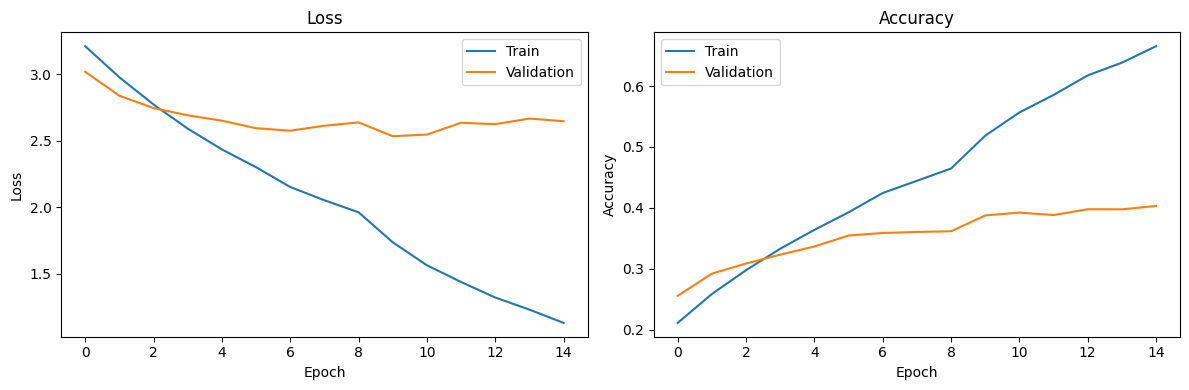

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# --- Loss ---
axes[0].plot(history.history['loss'],     label='Train')
axes[0].plot(history.history['val_loss'], label='Validation')
axes[0].set_title('Loss')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss')
axes[0].legend()

# --- Accuracy ---
axes[1].plot(history.history['accuracy'],     label='Train')
axes[1].plot(history.history['val_accuracy'], label='Validation')
axes[1].set_title('Accuracy')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Accuracy')
axes[1].legend()

plt.tight_layout()
plt.show()

In [29]:
y_pred = np.argmax(model.predict(x_test), axis=1)


375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step


In [31]:

best_epoch = int(np.argmin(history.history['val_loss']))
print(f"Best val_loss at epoch {best_epoch+1}: {history.history['val_loss'][best_epoch]:.4f}")
print(f"Val_loss at epoch {best_epoch+1}   : {history.history['val_loss'][best_epoch]:.4f}")
print(f"Val_loss at epoch {best_epoch+2}   : {history.history['val_loss'][best_epoch+1]:.4f}  ← starts rising")
print(f"Val_loss at last epoch ({len(history.history['val_loss'])}): {history.history['val_loss'][-1]:.4f}")

Best val_loss at epoch 10: 2.5352
Val_loss at epoch 10   : 2.5352
Val_loss at epoch 11   : 2.5478  ← starts rising
Val_loss at last epoch (15): 2.6483


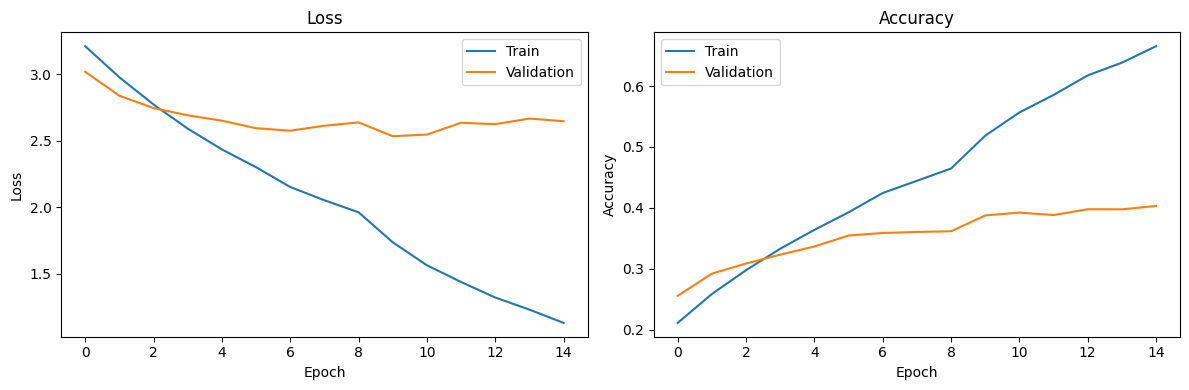

In [32]:

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Loss
axes[0].plot(history.history['loss'],     label='Train')
axes[0].plot(history.history['val_loss'], label='Validation')
axes[0].set_title('Loss')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss')
axes[0].legend()

# Accuracy
axes[1].plot(history.history['accuracy'],     label='Train')
axes[1].plot(history.history['val_accuracy'], label='Validation')
axes[1].set_title('Accuracy')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Accuracy')
axes[1].legend()

plt.tight_layout()
plt.show()

In [33]:

y_pred = np.argmax(model.predict(x_test), axis=1)
cm = confusion_matrix(y_test, y_pred)        # true labels first, predictions second

cm_off = cm.copy()
np.fill_diagonal(cm_off, 0)                  # ignore correct predictions

top = np.argsort(cm_off.flatten())[::-1][:10]   # 10 biggest mistakes
for k in top:
    true_i, pred_i = divmod(k, 100)
    print(f"{class_names[true_i]} -> predicted {class_names[pred_i]}: {cm_off[true_i, pred_i]} times")

375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step
whale -> predicted dolphin: 33 times
poppy -> predicted tulip: 24 times
tulip -> predicted rose: 23 times
shark -> predicted dolphin: 22 times
bear -> predicted elephant: 22 times
maple_tree -> predicted oak_tree: 22 times
willow_tree -> predicted maple_tree: 21 times
beetle -> predicted cockroach: 20 times
woman -> predicted girl: 19 times
couch -> predicted bed: 19 times


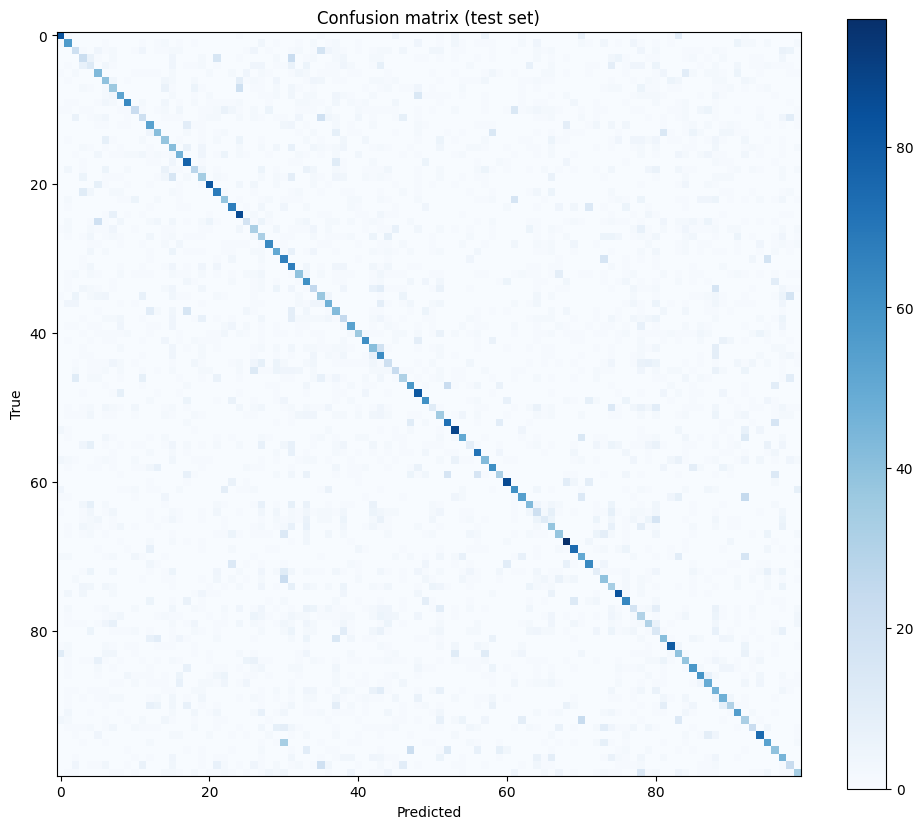

In [34]:
plt.figure(figsize=(12, 10))
plt.imshow(cm, cmap='Blues')
plt.colorbar()
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Confusion matrix (test set)')
plt.show()

In [35]:
per_class_acc = cm.diagonal() / cm.sum(axis=1)

best_idx  = np.argsort(per_class_acc)[::-1][:5]
worst_idx = np.argsort(per_class_acc)[:5]

print("=== 5 BEST classes ===")
for i in best_idx:
    print(f"  {class_names[i]:<20s} accuracy={per_class_acc[i]:.3f}  (n={cm[i].sum()})")

print("\n=== 5 WORST classes ===")
for i in worst_idx:
    print(f"  {class_names[i]:<20s} accuracy={per_class_acc[i]:.3f}  (n={cm[i].sum()})")

=== 5 BEST classes ===
  road                 accuracy=0.800  (n=120)
  orange               accuracy=0.733  (n=120)
  plain                accuracy=0.717  (n=120)
  cockroach            accuracy=0.717  (n=120)
  apple                accuracy=0.692  (n=120)

=== 5 WORST classes ===
  otter                accuracy=0.075  (n=120)
  seal                 accuracy=0.075  (n=120)
  rabbit               accuracy=0.092  (n=120)
  mouse                accuracy=0.092  (n=120)
  beaver               accuracy=0.100  (n=120)
